# In-class work 11. Equipment diagnostics and the risk procedures: FMEA, FTA, HAZOP, HAZID

Industrial AI, KBTU. Goes with Lecture 11, "Industrial equipment diagnostic with
machine learning methods. FMEA, HAZID, HAZOP, FTA: artificial intelligence improvements".

The object is the hydraulic test rig from week 3: a working circuit and a cooling circuit, 17
sensors, a 60-second load cycle repeated 2205 times. During the run the experimenters degraded
four components on purpose: the cooler, the valve, the pump and the accumulator. Here each cycle
is one row, the mean and the standard deviation of every sensor over the cycle.

Plants already run formal risk studies, where a team of engineers writes scores into a table.
Our question is what a diagnostic model can change in that table, and how to stop a model that
looks good from writing a false number into it.

1. the four procedures, and where data enters each one;
2. the rig and its four failure modes;
3. a diagnostic model, and the split that decides what you believe;
4. a one-sensor alarm against the model: probability of detection;
5. FMEA: the risk priority number before and after;
6. FTA: a fault tree with the monitor as a barrier;
7. HAZOP: are the causes in the worksheet visible in the data?
8. HAZID: free-text work orders and a hazard nobody listed.

Both data files come with the course repo (`data/hydraulic_cycles/`, `data/work_orders/`). Run
top to bottom with `Shift+Enter`, about one minute.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import itertools
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'hydraulic_cycles': None,
    'work_orders': None,
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1


---

# Part 1. Four procedures on one page

| | FMEA | FTA | HAZOP | HAZID |
|---|---|---|---|---|
| Name | Failure Mode and Effects Analysis | Fault Tree Analysis | Hazard and Operability study | Hazard Identification |
| Question | how can each part fail, and how bad is it? | which combinations of events cause this one accident? | what happens if a process parameter deviates? | what can hurt people or the plant at all? |
| Direction | bottom-up, part → effect | top-down, accident → causes | by process node, guide word × parameter | broad, early in a project |
| Output | table with S, O, D and RPN | tree, minimal cut sets, probability of the top event | worksheet: deviation, cause, consequence, safeguard | hazard register |
| What people usually supply | every score, from experience | base probabilities, from handbooks | causes, from a workshop | the list, from memory and checklists |
| Where a model can help | D from a measured detection rate, O from failure history | base probabilities from data; a monitor enters the tree as a barrier | checks which causes really move which parameter | reads thousands of work orders for hazards missing from the register |

Today we run each of the four once on the same rig. The engineers still sign the document; the
model only supplies measured numbers for some of its cells.

---

# Part 2. The rig and its four failure modes

Each component was held at a few grades, in a full factorial plan. The first grade is healthy.
The second is the earliest degradation, the one a monitor should catch.

| column | failure mode | grades, healthy first | early grade |
|---|---|---|---|
| `cooler` | cooler loses efficiency, % | 100, 20, 3 | 20 |
| `valve` | valve switches late, % of optimal | 100, 90, 80, 73 | 90 |
| `pump` | pump leaks internally | 0, 1, 2 | 1 |
| `accumulator` | accumulator loses gas pressure, bar | 130, 115, 100, 90 | 115 |

In [2]:
rig = pd.read_csv(dataset_folder("hydraulic_cycles") / "hydraulic_cycles.csv")
FEATURES = [c for c in rig.columns if c.endswith(("_mean", "_std"))]
X = rig[FEATURES].to_numpy()

# letter: the name of the component in the fault tree of Part 6
MODES = {
    "cooler": dict(healthy=100, early=20, letter="C",
                   name="cooler loses efficiency"),
    "valve": dict(healthy=100, early=90, letter="V",
                  name="valve switches late"),
    "pump": dict(healthy=0, early=1, letter="P",
                 name="pump leaks internally"),
    "accumulator": dict(healthy=130, early=115, letter="A",
                        name="accumulator loses gas pressure"),
}


def degraded(m):
    # True for every cycle where component m is not at its healthy grade
    return (rig[m] != MODES[m]["healthy"]).to_numpy()


print(rig.shape, "|", len(FEATURES), "features")
for m, info in MODES.items():
    healthy_first = info["healthy"] < 50
    counts = rig[m].value_counts().sort_index(ascending=healthy_first)
    print(f"{m:12s} cycles per grade: {counts.to_dict()}")

(2205, 40) | 34 features
cooler       cycles per grade: {100: 741, 20: 732, 3: 732}
valve        cycles per grade: {100: 1125, 90: 360, 80: 360, 73: 360}
pump         cycles per grade: {0: 1221, 1: 492, 2: 492}
accumulator  cycles per grade: {130: 599, 115: 399, 100: 399, 90: 808}


What does the plant already have? Usually one limit on one sensor. For each failure mode we pick
the single feature that separates degraded from healthy cycles best, **using all the data**, in
hindsight. That is generous to the alarm: nobody knows the best sensor before the first failure.

The yardstick is the AUC. It is the probability that a randomly chosen degraded cycle has a
higher value of the feature than a randomly chosen healthy one. 0.5 means the feature ranks the
two groups at random, 1.0 means every degraded cycle is above every healthy one. An AUC of 0.2
is as useful as 0.8, with the sign flipped, so we keep the direction together with the feature.

cooler       best single feature CE_mean    AUC degraded vs healthy 1.000
valve        best single feature SE_mean    AUC degraded vs healthy 0.782


pump         best single feature SE_mean    AUC degraded vs healthy 0.990
accumulator  best single feature PS1_mean   AUC degraded vs healthy 0.727


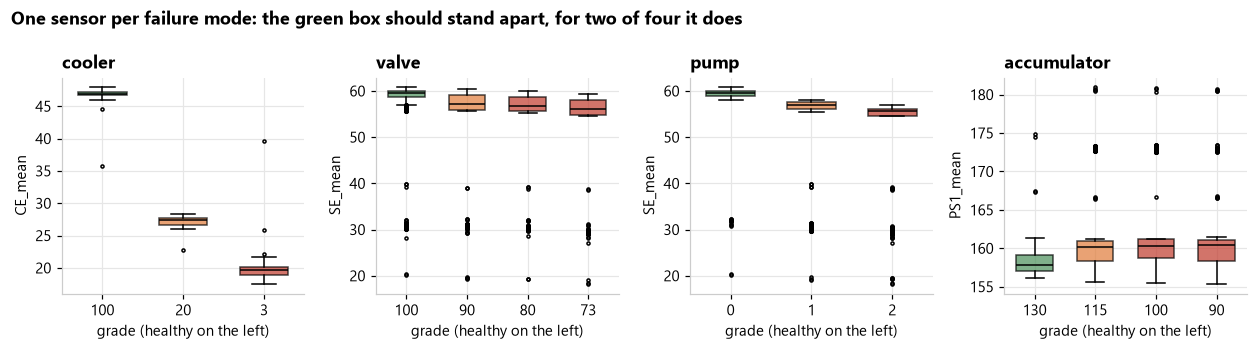

In [3]:
best_sensor = {}        # mode -> (feature, sign); sign * feature grows with degradation
for m in MODES:
    auc = pd.Series({f: roc_auc_score(degraded(m), rig[f]) for f in FEATURES})
    f = (auc - 0.5).abs().idxmax()
    sign = 1 if auc[f] > 0.5 else -1
    best_sensor[m] = (f, sign)
    strength = max(auc[f], 1 - auc[f])
    print(f"{m:12s} best single feature {f:10s} AUC degraded vs healthy {strength:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.2))
for ax, (m, info) in zip(axes, MODES.items()):
    f, _ = best_sensor[m]
    grades = sorted(rig[m].unique(), reverse=info["healthy"] > 50)
    values = [rig.loc[rig[m] == g, f] for g in grades]
    bp = ax.boxplot(values, widths=0.6, patch_artist=True,
                    medianprops=dict(color="black"), flierprops=dict(markersize=2))

    # green: healthy, orange: the early grade, red: worse
    colour_of = {info["healthy"]: GREEN, info["early"]: ORANGE}
    for patch, g in zip(bp["boxes"], grades):
        patch.set_facecolor(colour_of.get(g, RED))
        patch.set_alpha(0.7)
    ax.set_xticklabels(grades)
    ax.set(title=m, xlabel="grade (healthy on the left)", ylabel=f)
title = ("One sensor per failure mode: the green box should stand apart, "
         "for two of four it does")
fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

---

# Part 3. A diagnostic model, and the split that decides what you believe

The model is a random forest per failure mode, degraded or healthy, on all 34 features. The
other components vary at the same time, as they would on a real machine.

We score it on held-out cycles, split three ways.

- **Random 5-fold.** Any cycle can land on either side.
- **Condition sets.** Cycles with the same four grades ran one after another, about 11 at a
  time. A whole set goes to one side.
- **Time blocks.** The 2205 cycles are cut into 20 consecutive blocks of about 110, and whole
  blocks go to one side. The model is tested on a period of the run it has not seen, which is
  what a deployed model faces every day.

In [4]:
# a new condition set starts at every cycle where any of the four grades changes
grade_changed = rig[list(MODES)].diff().abs().sum(axis=1).gt(0)
state = grade_changed.cumsum().to_numpy()                 # condition set id
block = (np.arange(len(rig)) * 20) // len(rig)            # time block id
print("condition sets:", state.max() + 1, "| time blocks:", block.max() + 1)

SPLITS = {
    "random 5-fold":  list(KFold(5, shuffle=True, random_state=0).split(X)),
    "condition sets": list(GroupKFold(5).split(X, groups=state)),
    "time blocks":    list(GroupKFold(5).split(X, groups=block)),
}


def held_out_scores(splits):
    # one random forest per failure mode;
    # returns {mode: held-out P(degraded) of every cycle}
    scores = {}
    for m in MODES:
        y = degraded(m).astype(int)
        s = np.zeros(len(y))
        for tr, te in splits:
            rf = RandomForestClassifier(150, n_jobs=-1, random_state=0)
            rf.fit(X[tr], y[tr])
            s[te] = rf.predict_proba(X[te])[:, 1]
        scores[m] = s
    return scores


SCORES = {name: held_out_scores(sp) for name, sp in SPLITS.items()}
auc_table = pd.DataFrame({name: {m: roc_auc_score(degraded(m), s[m]) for m in MODES}
                          for name, s in SCORES.items()})
print(auc_table.round(3).to_string())

condition sets: 194 | time blocks: 20


             random 5-fold  condition sets  time blocks
cooler               1.000           1.000        1.000
valve                0.999           0.964        0.976
pump                 1.000           1.000        1.000
accumulator          1.000           0.871        0.843


The cooler and the pump are solved under any split. The accumulator falls from AUC 1.000 under
the random split to 0.843 on time blocks.

What leaked? Consecutive cycles under the same grades are near copies of each other, and the oil
temperature drifts slowly over the run. With random folds every test cycle has a neighbour in
training, so the forest can recognise *when* a cycle was recorded. The accumulator grade changed
only about a dozen times in 2205 cycles, so for this component "when" and "which grade" are
almost the same thing.

---

# Part 4. A one-sensor alarm against the model

AUC averages over all thresholds, and a plant runs one. So we fix the price: **the monitor may
raise a false alarm on 5 % of healthy cycles**, the same for both. Then we ask what share of the
*early-grade* cycles it catches. That share is the **probability of detection**, POD:

$$\text{POD} = P(\text{alarm} \mid \text{early grade of this mode}), \qquad
\text{threshold chosen so that } P(\text{alarm} \mid \text{healthy}) = 0.05.$$

The threshold is the 95 % quantile of the scores of healthy cycles. On the ROC curve this is the
point at a false positive rate of 0.05, read for the early grade only. Two monitors with the same
AUC can have very different POD, because the area counts the whole curve and the plant lives at
one point of it.

We read the threshold off the pooled held-out scores. A plant has to set it from past data only,
so its numbers will be somewhat worse.

             alarm, best sensor  model, random split  model, condition sets  model, time blocks
cooler                    1.000                1.000                  1.000               1.000
valve                     0.142                1.000                  0.456               0.714
pump                      1.000                1.000                  1.000               1.000
accumulator               0.203                1.000                  0.852               0.168


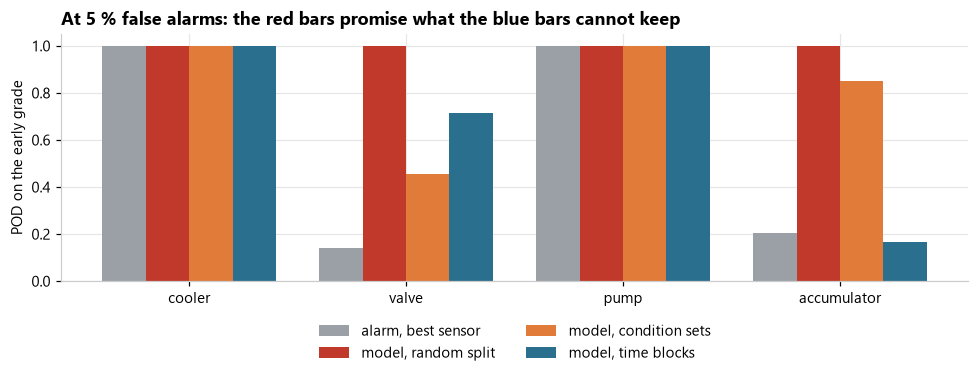

In [5]:
def pod(score, m, far=0.05):
    # POD on the early grade at a fixed false alarm rate on healthy cycles
    grade = rig[m].to_numpy()
    threshold = np.quantile(score[grade == MODES[m]["healthy"]], 1 - far)
    return float((score[grade == MODES[m]["early"]] > threshold).mean())


alarm_score = {m: sign * rig[f].to_numpy() for m, (f, sign) in best_sensor.items()}
POD = pd.DataFrame({
    "alarm, best sensor":     {m: pod(alarm_score[m], m) for m in MODES},
    "model, random split":    {m: pod(SCORES["random 5-fold"][m], m) for m in MODES},
    "model, condition sets":  {m: pod(SCORES["condition sets"][m], m) for m in MODES},
    "model, time blocks":     {m: pod(SCORES["time blocks"][m], m) for m in MODES},
})
print(POD.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(MODES))
for i, (col, c) in enumerate(zip(POD.columns, [GREY, RED, ORANGE, BLUE])):
    ax.bar(x + (i - 1.5) * 0.2, POD[col], 0.2, color=c, label=col)
ax.set_xticks(x, POD.index)
ax.set(ylabel="POD on the early grade", ylim=(0, 1.05),
       title="At 5 % false alarms: the red bars promise what the blue bars cannot keep")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

For the cooler and the pump one feature already catches the early grade at POD 1.00, and the
model adds nothing. For the valve, POD goes from 0.14 to 0.71 on time blocks: here the model
earns its place. For the accumulator it is 0.20 for the alarm and 0.17 for the model on time
blocks, no gain at all.

The random split reports 1.00 everywhere. The two honest splits disagree with each other (valve
0.46 and 0.71, accumulator 0.85 and 0.17) because they answer different questions: condition
sets still put neighbouring periods of the same accumulator run on both sides. We carry time
blocks into the FMEA, since they look most like deployment.

---

# Part 5. FMEA: the risk priority number before and after

Each failure mode gets three scores from 1 to 10, and their product is the **risk priority
number**:

$$\text{RPN} = S \times O \times D.$$

- **S**, severity: how bad the effect is. A model cannot change it.
- **O**, occurrence: how often the cause appears, from failure history. This rig cannot supply
  it, because the experimenters set its fault frequencies.
- **D**, detection: how likely the failure escapes before it does harm. D = 10 means nothing
  will catch it, D = 1 means it is caught almost surely. Here a measurement can replace an
  opinion.

Usually D comes from a table of words ("moderate chance of detection"). We replace it with a
scale over the measured POD. The scale below was written for this course; a plant writes its own.

| POD at least | 0.99 | 0.95 | 0.90 | 0.80 | 0.70 | 0.50 | 0.30 | 0.15 | 0.05 | below |
|---|---|---|---|---|---|---|---|---|---|---|
| D | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |

S and O below are assumed for a press line driven by such a power unit, the way a reliability
engineer might write them.

             S  O  D before  RPN before  D if we trust the random split  RPN if we trust the random split  D after  RPN after
cooler       5  6         1          30                               1                                30        1         30
valve        7  4         9         252                               1                                28        5        140
pump         8  3         1          24                               1                                24        1         24
accumulator  6  5         8         240                               1                                30        8        240

total RPN before 546 | promised by the random split 112 | after, honest 434


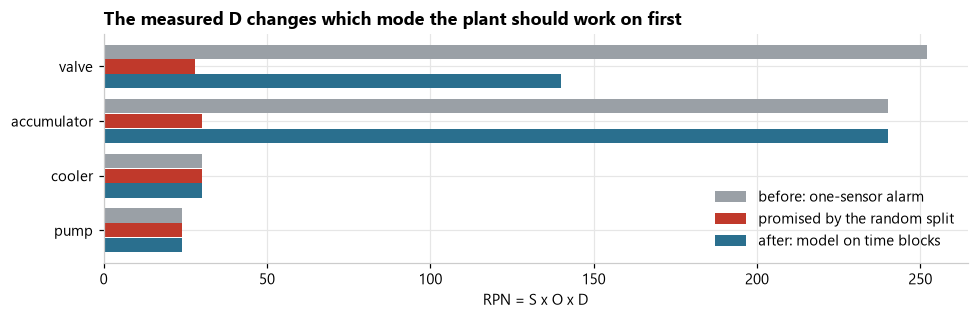

In [6]:
POD_EDGES = [0.99, 0.95, 0.90, 0.80, 0.70, 0.50, 0.30, 0.15, 0.05]   # D = 1..9; below: 10


def detection_rating(p):
    for d, edge in enumerate(POD_EDGES, start=1):
        if p >= edge:
            return d
    return 10


fmea = pd.DataFrame({"S": {"cooler": 5, "valve": 7, "pump": 8, "accumulator": 6},
                     "O": {"cooler": 6, "valve": 4, "pump": 3, "accumulator": 5}})
for label, col in [("before", "alarm, best sensor"),
                   ("if we trust the random split", "model, random split"),
                   ("after", "model, time blocks")]:
    fmea[f"D {label}"] = POD[col].map(detection_rating)
    fmea[f"RPN {label}"] = fmea["S"] * fmea["O"] * fmea[f"D {label}"]
print(fmea.to_string())
print("\ntotal RPN before", fmea["RPN before"].sum(),
      "| promised by the random split", fmea["RPN if we trust the random split"].sum(),
      "| after, honest", fmea["RPN after"].sum())

fig, ax = plt.subplots(figsize=(9, 3))
order = fmea["RPN before"].sort_values().index
rows = np.arange(len(order))
bars = [  # column, shift of the bar, colour, legend
    ("RPN before", 0.27, GREY, "before: one-sensor alarm"),
    ("RPN if we trust the random split", 0.0, RED, "promised by the random split"),
    ("RPN after", -0.27, BLUE, "after: model on time blocks"),
]
for col, shift, colour, label in bars:
    ax.barh(rows + shift, fmea.loc[order, col], 0.26, color=colour, label=label)
ax.set_yticks(rows, order)
ax.set(xlabel="RPN = S x O x D",
       title="The measured D changes which mode the plant should work on first")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

The honest result: the valve goes from RPN 252 to 140, the accumulator stays at 240, and the
total falls from 546 to 434. The accumulator is now the first item on the action list, and the
model does nothing for it. The next piece of work there is a pressure-decay test or a sensor
that sees the gas charge. A better forest will not replace either.

Had we trusted the random split, the report to the plant manager would say total RPN 112, every
mode at 30 or below, nothing left to do.

RPN is convenient, but its arithmetic is bad. S, O and D are ordinal scales: D = 8 does not mean
twice as bad as D = 4, it only means worse. Multiplying ranks gives a number whose differences
mean nothing. Three quick checks:

In [7]:
products = {s * o * d for s in range(1, 11) for o in range(1, 11) for d in range(1, 11)}
print(f"S x O x D with values 1..10 gives only {len(products)} different RPN values, "
      "not 1000")

a, b = (10, 2, 2), (2, 5, 4)
print(f"S, O, D = {a}: RPN {np.prod(a)}   (a catastrophe, rare, easy to catch)")
print(f"S, O, D = {b}: RPN {np.prod(b)}   "
      "(a nuisance, moderately frequent, hard to catch)")

rpn = fmea["S"] * fmea["O"] * fmea["D after"]
top = rpn.idxmax()
print("\nOne point of disagreement on D of the top mode:")
for delta in (-1, 0, 1):
    d = fmea.loc[top, "D after"] + delta
    print(f"  D = {d}: RPN of {top} = {fmea.loc[top, 'S'] * fmea.loc[top, 'O'] * d}")

S x O x D with values 1..10 gives only 120 different RPN values, not 1000
S, O, D = (10, 2, 2): RPN 40   (a catastrophe, rare, easy to catch)
S, O, D = (2, 5, 4): RPN 40   (a nuisance, moderately frequent, hard to catch)

One point of disagreement on D of the top mode:
  D = 7: RPN of accumulator = 210
  D = 8: RPN of accumulator = 240
  D = 9: RPN of accumulator = 270


The automotive FMEA handbook of AIAG and VDA (2019) dropped RPN in favour of **Action Priority**,
a lookup table that gives more weight to S. Many plants still report RPN, and the syllabus asks
for it. Use it to rank, and do not divide or average it.

A lower D does not make the failure rarer or milder. It changes when you find out.

---

# Part 6. FTA: the monitor as a barrier in a fault tree

FMEA looks at one failure mode at a time. A fault tree starts from one accident and asks which
**combinations** of events cause it. Our top event: *an unplanned stop of the press line within
a year*.

- **AND gate:** the output occurs if all inputs occur. Protection appears as an AND: the
  degradation happens *and* the monitor misses it.
- **OR gate:** the output occurs if any input occurs.
- **Minimal cut set:** a smallest set of basic events that together cause the top event.

For independent inputs with probabilities $p_i$ the gates are simple arithmetic:

$$P(\text{AND}) = \prod_i p_i, \qquad P(\text{OR}) = 1 - \prod_i (1 - p_i).$$

The AND multiplies small numbers, which is why a barrier helps: a degradation with probability
0.25 behind a monitor that misses it half the time leaves 0.125. The OR formula is the chance
that not every input stays quiet.

The basic events: a component degrades during the year ($C, V, P, A$); the monitor misses it
($m_C, m_V, m_P, m_A$, each with probability $1 - \text{POD}$); a hose bursts with no warning
($H$). A one-sensor alarm is wired straight to its transmitter. A model needs all 17 sensors and
the data link to the historian, so its tree gains one more event: the data link or the server is
down ($L$).

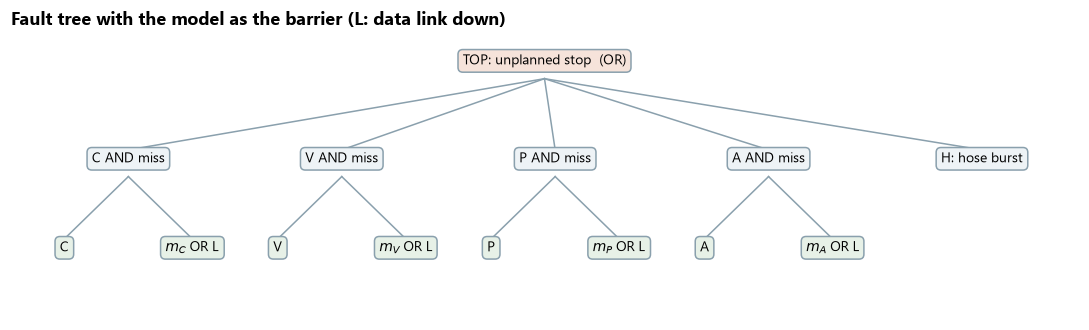

In [8]:
LETTERS = [info["letter"] for info in MODES.values()]       # C, V, P, A


def fig_tree(after):
    fig, ax = plt.subplots(figsize=(10, 3.1))
    ax.set(xlim=(0, 100), ylim=(0, 32))
    ax.axis("off")

    def box(x, y, text, c="#eef3f6"):
        ax.text(x, y, text, ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.35", fc=c, ec="#8aa0ad"))

    def line(x0, y0, x1, y1):
        ax.plot([x0, x1], [y0, y1], color="#8aa0ad", lw=1, zorder=0)

    box(50, 29, "TOP: unplanned stop  (OR)", "#f6e3da")
    xs = [11, 31, 51, 71, 91]
    labels = [f"{n} AND miss" for n in LETTERS] + ["H: hose burst"]
    for x, t in zip(xs, labels):
        line(50, 27, x, 19)
        box(x, 18, t)
    for x, n in zip(xs, LETTERS):
        line(x, 16, x - 6, 9)
        line(x, 16, x + 6, 9)
        box(x - 6, 8, n, "#e7f1e7")
        box(x + 6, 8, f"$m_{n}$ OR L" if after else f"$m_{n}$", "#e7f1e7")
    if after:
        ax.set_title("Fault tree with the model as the barrier (L: data link down)")
    else:
        ax.set_title("Fault tree with one-sensor alarms as the barrier")
    fig.tight_layout()
    plt.show()


fig_tree(after=True)

Below, the tree is written as nested tuples, its minimal cut sets are found by expanding the
gates, and the top probability is computed exactly by enumerating all $2^{10}$ on/off states of
the basic events. Before the model the five branches share no event, so the OR formula above
must give the same number; the cell prints both as a check. After the model every branch
contains $L$, the branches are no longer independent, and only the enumeration is right.

In [9]:
def tree(with_link):
    # top event: OR over "component x degrades AND its monitor misses", and the hose burst
    def miss(x):
        if with_link:
            return ("OR", f"m{x}", "L")
        return f"m{x}"

    return ("OR", *[("AND", x, miss(x)) for x in LETTERS], "H")


def cut_sets(node):
    # minimal cut sets of a tree written as nested ("AND"/"OR", child, child, ...)
    if isinstance(node, str):
        return [frozenset([node])]
    op, *kids = node
    kid_sets = [cut_sets(k) for k in kids]
    if op == "OR":
        out = [c for s in kid_sets for c in s]
    else:
        out = [frozenset().union(*combo) for combo in itertools.product(*kid_sets)]
    out = set(out)
    return [c for c in out if not any(o < c for o in out)]


def top_probability(cuts, p):
    # exact probability of the top event: enumerate all 2^n states of the basic events
    names = sorted(p)
    prob = np.array([p[x] for x in names])
    n = len(names)

    # every on/off state of the n basic events (one row each) and its probability
    codes = np.arange(2 ** n)[:, None]
    states = ((codes >> np.arange(n)) & 1).astype(bool)
    weight = np.prod(np.where(states, prob, 1 - prob), axis=1)

    # the top event happens in a state where all events of some cut set are on
    fails = np.zeros(len(states), bool)
    for c in cuts:
        fails |= states[:, [names.index(x) for x in c]].all(axis=1)
    return float(weight[fails].sum())


BASE = {"C": 0.20, "V": 0.15, "P": 0.10, "A": 0.25, "H": 0.03}   # assumed, for one year
P_LINK = 0.02                                          # data link or server down

miss_before, miss_after = {}, {}       # P(the monitor misses), 1 - POD
for m, info in MODES.items():
    event = f"m{info['letter']}"
    miss_before[event] = 1 - POD.loc[m, "alarm, best sensor"]
    miss_after[event] = 1 - POD.loc[m, "model, time blocks"]
p_before = dict(BASE, **miss_before)
p_after = dict(BASE, **miss_after, L=P_LINK)

cuts_before = cut_sets(tree(False))
cuts_after = cut_sets(tree(True))
P_before = top_probability(cuts_before, p_before)
P_after = top_probability(cuts_after, p_after)
print(f"minimal cut sets: {len(cuts_before)} before, {len(cuts_after)} after")
print(f"P(unplanned stop in a year): before {P_before:.4f}, after {P_after:.4f}")

branches = [p_before[x] * p_before[f"m{x}"] for x in LETTERS] + [p_before["H"]]
P_independent = 1 - np.prod([1 - q for q in branches])
print(f"before, as independent branches 1 - prod(1 - p): {P_independent:.4f}")

# the same number by brute force, as a check on the enumeration
rng = np.random.default_rng(0)
draws = {x: rng.random(1_000_000) < q for x, q in p_after.items()}
mc = np.zeros(1_000_000, bool)
for c in cuts_after:
    mc |= np.all([draws[x] for x in c], axis=0)
print(f"Monte Carlo check of 'after': {mc.mean():.4f}")

importance = {}
for x in sorted(p_after):
    t1 = top_probability(cuts_after, dict(p_after, **{x: 1.0}))
    t0 = top_probability(cuts_after, dict(p_after, **{x: 0.0}))
    importance[x] = {"p": p_after[x], "Birnbaum": t1 - t0,
                     "Fussell-Vesely": 1 - t0 / P_after}
importance_table = pd.DataFrame(importance).T
importance_table = importance_table.sort_values("Fussell-Vesely", ascending=False)
print("\nImportance of each basic event, model in place:")
print(importance_table.round(3).to_string())

minimal cut sets: 5 before, 9 after
P(unplanned stop in a year): before 0.3233, after 0.2705
before, as independent branches 1 - prod(1 - p): 0.3233
Monte Carlo check of 'after': 0.2708

Importance of each basic event, model in place:
       p  Birnbaum  Fussell-Vesely
A  0.250     0.769           0.711
mA 0.832     0.227           0.700
V  0.150     0.226           0.125
mV 0.286     0.113           0.119
H  0.030     0.752           0.083
L  0.020     0.290           0.021
C  0.200     0.011           0.008
P  0.100     0.010           0.004
mC 0.000     0.144           0.000
mP 0.000     0.072           0.000


Two importance measures read the tree from the side of one event $x$:

$$I_B(x) = P(\text{top} \mid x) - P(\text{top} \mid \text{no } x), \qquad
I_{FV}(x) = 1 - \frac{P(\text{top} \mid \text{no } x)}{P(\text{top})}.$$

Birnbaum asks how much the top event hangs on $x$ if $x$ happens. Fussell–Vesely asks what share
of the top-event probability would disappear if $x$ could never occur, so it also weighs how
likely $x$ is.

The monitor lowers the probability of an unplanned stop from 0.323 to 0.271, by 16 %. About 70 %
of what remains passes through the accumulator (Fussell–Vesely of $A$ and $m_A$), which agrees
with the FMEA. The hose burst has Birnbaum 0.75, the second largest: if it happens, the line stops
whatever else is true. Its share is only 8 % because a burst is rare. $m_C$ and $m_P$ have a
Birnbaum of 0.14 and 0.07 and no share at all, because their probability is already zero.

The base probabilities are assumed. At a plant they would come from the maintenance history.

The model is a shared barrier. Every barrier fed by the same data link fails together: a
**common cause**. How unreliable can the link be before the model stops paying off?

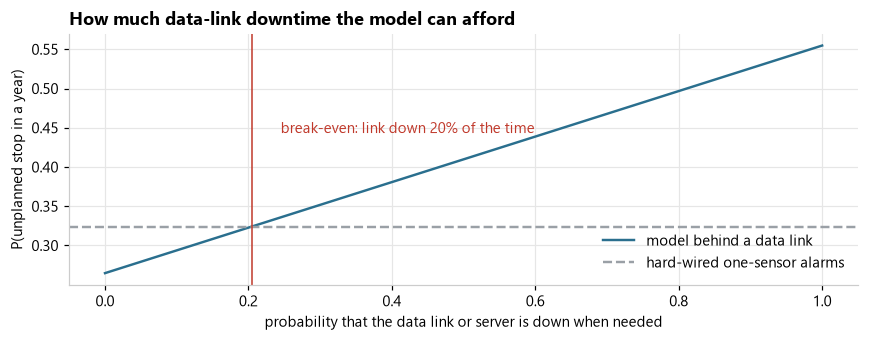

break-even at 0.205


In [10]:
links = np.linspace(0, 1, 201)
P_curve = np.array([top_probability(cuts_after, dict(p_after, L=q)) for q in links])
worse = P_curve > P_before                # the model loses to the plain alarms
cross = links[np.argmax(worse)] if worse.any() else None

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(links, P_curve, color=BLUE, label="model behind a data link")
ax.axhline(P_before, color=GREY, ls="--", label="hard-wired one-sensor alarms")
if cross is not None:
    ax.axvline(cross, color=RED, lw=1)
    ax.annotate(f"break-even: link down {cross:.0%} of the time", (cross, P_before),
                xytext=(cross + 0.04, P_before + 0.12), color=RED)
ax.set(xlabel="probability that the data link or server is down when needed",
       ylabel="P(unplanned stop in a year)",
       title="How much data-link downtime the model can afford")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
print("break-even at", None if cross is None else f"{cross:.3f}")

At 2 % downtime the link costs almost nothing. Beyond about 20 % the plain alarms win. $L$ stands
for more than a broken cable: a drifting sensor or a model that was never retrained also takes
the barrier away from all modes at once. The comparison flatters the alarms a little, since a
real transmitter fails too and we left that out of their tree.

**A fault tree counts the ways to fail. How does the same arithmetic read for reliability, the
probability that the line keeps working?**

<details><summary>Answer</summary>

Reliability is $R = 1 - P(\text{failure})$. A series system works only if every part works, so
$R = \prod_i R_i$. A parallel (redundant) system works if at least one part works, so
$R = 1 - \prod_i (1 - R_i)$. These are the OR and the AND gates of Part 6, written for success
instead of failure.

In our tree each branch "$x$ degrades AND the monitor misses" is a parallel pair: the line
survives that branch if the component holds or the monitor catches it, so the pair fails with
probability $p_x m_x$. The top OR puts the five branches in series. With the one-sensor alarms
$R = (1 - p_H) \prod_x (1 - p_x m_x) = 1 - 0.323 = 0.677$, and the cell below checks it.

</details>

In [11]:
# the tree before the model as a reliability diagram: five blocks in series
R_blocks = [1 - q for q in branches]       # a block works unless its branch fails
print(f"R of the line = prod R_i = {np.prod(R_blocks):.4f}")
print(f"1 - P(top event)         = {1 - P_before:.4f}")

R of the line = prod R_i = 0.6767
1 - P(top event)         = 0.6767


---

# Part 7. HAZOP: are the causes in the worksheet visible in the data?

A HAZOP team walks through the plant node by node and combines **guide words** (NO, MORE, LESS,
REVERSE, OTHER THAN) with **process parameters**. For each deviation it writes causes,
consequences and safeguards. The causes come from a workshop, so they are hypotheses.

The list below is a fragment of such a worksheet for the working circuit. A history with
labelled faults lets us test each link. For a guide word and a parameter we compute the AUC of
"this component is degraded" against the parameter, oriented along the guide word (for LESS we
score $-x$). By the ranking reading of AUC from Part 2, 0.5 means the component does not move
the parameter that way, 1 means it always does, and a value well below 0.5 means it moves the
parameter the *other* way.

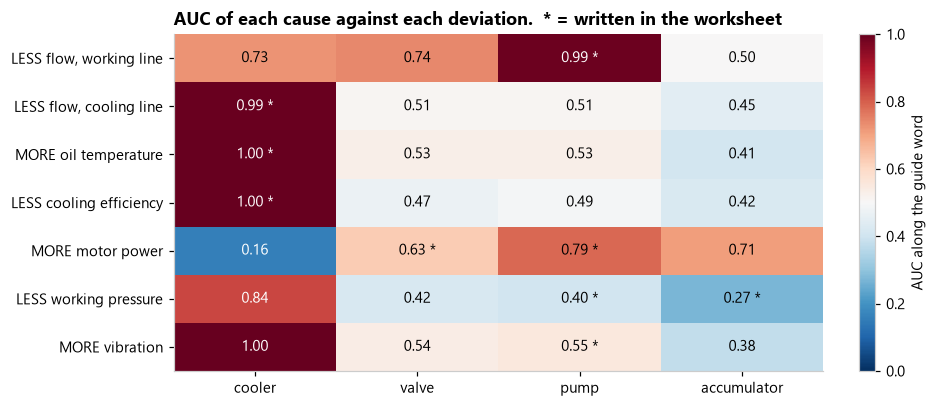

LESS flow, working line   confirmed ['pump']  not visible []  not in the worksheet []
LESS flow, cooling line   confirmed ['cooler']  not visible []  not in the worksheet []
MORE oil temperature      confirmed ['cooler']  not visible []  not in the worksheet []
LESS cooling efficiency   confirmed ['cooler']  not visible []  not in the worksheet []
MORE motor power          confirmed ['pump']  not visible ['valve']  not in the worksheet []
LESS working pressure     confirmed []  not visible ['pump', 'accumulator']  not in the worksheet ['cooler']
MORE vibration            confirmed []  not visible ['pump']  not in the worksheet ['cooler']


In [12]:
HAZOP = [  # guide word, parameter, feature, direction, causes the team wrote down
    ("LESS", "flow, working line",  "FS1_mean", -1, ["pump"]),
    ("LESS", "flow, cooling line",  "FS2_mean", -1, ["cooler"]),
    ("MORE", "oil temperature",     "TS1_mean", +1, ["cooler"]),
    ("LESS", "cooling efficiency",  "CE_mean",  -1, ["cooler"]),
    ("MORE", "motor power",         "EPS1_mean", +1, ["pump", "valve"]),
    ("LESS", "working pressure",    "PS1_mean", -1, ["pump", "accumulator"]),
    ("MORE", "vibration",           "VS1_mean", +1, ["pump"]),
]
STRONG = 0.75           # AUC from which we call a cause visible in the data

# AUC of "component m is degraded" against each parameter, oriented along its guide word
auc_by_mode = {}
for m in MODES:
    auc_by_mode[m] = [roc_auc_score(degraded(m), d * rig[f]) for _, _, f, d, _ in HAZOP]
link = pd.DataFrame(auc_by_mode, index=[f"{g} {p}" for g, p, *_ in HAZOP])

fig, ax = plt.subplots(figsize=(8.6, 3.8))
im = ax.imshow(link.to_numpy(), cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(MODES)), link.columns)
ax.set_yticks(range(len(link)), link.index)
for i, (*_, causes) in enumerate(HAZOP):
    for j, m in enumerate(link.columns):
        value = link.iloc[i, j]
        text = f"{value:.2f}" + (" *" if m in causes else "")
        colour = "white" if abs(value - 0.5) > 0.3 else "black"
        ax.text(j, i, text, ha="center", va="center", color=colour)
ax.set_title("AUC of each cause against each deviation.  * = written in the worksheet")
fig.colorbar(im, ax=ax, label="AUC along the guide word", fraction=0.03)
fig.tight_layout()
plt.show()

for i, (g, p, f, d, causes) in enumerate(HAZOP):
    row = link.iloc[i]
    confirmed = [c for c in causes if row[c] >= STRONG]
    unsupported = [c for c in causes if row[c] < STRONG]
    missing = [m for m in MODES if m not in causes and row[m] >= STRONG]
    print(f"{g:4s} {p:20s} confirmed {confirmed}  not visible {unsupported}  "
          f"not in the worksheet {missing}")

Three kinds of finding.

- **Confirmed.** A leaking pump lowers the flow in the working line (0.99). A degraded cooler
  raises the oil temperature and lowers the cooling efficiency (1.00).
- **Written down, not visible.** The accumulator and the pump were listed as causes of LESS
  working pressure. For the accumulator the AUC is 0.27: when it loses gas, the mean pressure
  goes **up**. Pump leakage against vibration gives 0.55.
- **Not written down.** The cooler moves almost everything, up to 1.00 on vibration. Warm oil is
  thinner, so that is plausible. Be careful, though: the cooler grade changed only three times
  in the whole run, and any slow drift of the rig looks like a cooler effect in this table.

The data raises questions for the team and does not settle them. A cycle mean hides a short
pressure dip, and a cause this rig never produced stays a valid row in the worksheet.

---

# Part 8. HAZID: a hazard nobody wrote down

A hazard register is written from memory and checklists. Meanwhile the plant keeps a maintenance
system full of free text. Nobody reads 400 work orders in a workshop, but a topic model can group
them.

The work orders here are **simulated** for this class; real ones are far messier. The method is
the same as on real data:

1. keep the unplanned orders;
2. turn each text into a TF-IDF vector, one weight per word or word pair: frequent in this order,
   rare in the others;
3. factorise the order-by-term matrix with NMF, $\mathbf{A} \approx \mathbf{W}\mathbf{H}$, all
   entries non-negative. Each row of $\mathbf{H}$ is a topic, a weighted list of terms, and row
   $i$ of $\mathbf{W}$ says how much of each topic order $i$ contains. Non-negativity means a
   document can only *add* topics, so topics come out as recognisable groups of words;
4. compare each topic with the register by the cosine $\cos(\mathbf{h}, \mathbf{r}) =
   \mathbf{h}^\top\mathbf{r} / (\lVert\mathbf{h}\rVert\,\lVert\mathbf{r}\rVert)$ between the
   topic vector and the TF-IDF vector of each register entry. A cosine near 0 means the two share
   almost no words.

A topic that resembles no entry is a candidate for the HAZID team.

In [13]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

orders = pd.read_csv(dataset_folder("work_orders") / "work_orders.csv")
print(orders["type"].value_counts().to_dict())
# planned orders (filter changes) carry no hazard signal
orders = orders[orders["type"] == "unplanned"].reset_index(drop=True)
print(len(orders), "unplanned work orders, for example:")
for t in orders["text"].head(4):
    print("  -", t)

REGISTER = {
    "fire":     "hot oil leak ignition fire at the power unit",
    "hose":     "burst hose oil jet injection injury high pressure",
    "burn":     "burn from hot surfaces of the cooler pipe and tank",
    "noise":    "noise exposure near the pump hearing protection",
    "electric": "electric shock live parts motor terminal box earth fault",
}

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3)
A = tfidf.fit_transform(orders["text"])                 # orders x terms
K = 6                                                   # number of topics, our choice
nmf = NMF(n_components=K, init="nndsvda", random_state=0, max_iter=800)
nmf.fit(A)
W = nmf.transform(A)                                    # orders x K
H = nmf.components_                                     # K x terms

# cosine of every topic with every register entry
H_unit = H / np.linalg.norm(H, axis=1, keepdims=True)
R = tfidf.transform(REGISTER.values()).toarray()
R_unit = R / np.linalg.norm(R, axis=1, keepdims=True)
cos = H_unit @ R_unit.T                                 # K x register entries

words = np.array(tfidf.get_feature_names_out())
top_words = [", ".join(words[np.argsort(h)[::-1][:6]]) for h in H]
topics = pd.DataFrame({
    "orders": np.bincount(W.argmax(axis=1), minlength=K),
    "closest register entry": [list(REGISTER)[i] for i in cos.argmax(axis=1)],
    "cosine": cos.max(axis=1),
    "top words": top_words,
}).sort_values("cosine")
print()
print(topics.round(3).to_string())

{'unplanned': 304, 'planned': 110}
304 unplanned work orders, for example:
  - Hot surface warning label missing on the cooler outlet pipe.
  - Hot surface warning label missing on the cooler outlet pipe. Reported by the night shift.
  - Electric shock from the pump motor casing, earth lead broken.
  - Smell of burning oil near the power unit, leak traced to a fitting.

   orders closest register entry  cosine                                                                         top words
4      34                   hose   0.095  accumulator, residual pressure, residual, pressure, accumulator charged, charged
0      66                   fire   0.423                  power unit, unit, power, dripping, oil dripping, dripping heater
3      50                   burn   0.423                             pipe, cooler, hot, cooler outlet, outlet, outlet pipe
5      57               electric   0.427                          motor, live, motor terminal, terminal, terminal box, box
1      37   

Five topics land on register entries, with cosines from 0.42 to 0.58. The sixth has a cosine of
0.095: 34 orders about **accumulator, residual pressure, charged**. Fitters opened lines while
the accumulator still held pressure, with the lockout done on the motor only. The register has no
entry for stored energy during maintenance. Each order on its own looks like a near miss, and
only the group of 34 shows a pattern, so this is a candidate row for the next HAZID.

The number of topics is our choice. With eight or more, a filler topic appears that also matches
nothing, and a person has to read the orders to see which one is real.

Large language models do the same job with less set-up, and they can draft a whole worksheet.
They can also invent a plausible cause that never happened. Whatever tool produces the list, a
person with plant experience reads it and signs it.

---

## Further reading

- Survival analysis models the time until a failure. It also uses the units that have not failed
  yet (censored records), which a plain regression on lifetimes would have to throw away. The
  usual first model for a component is the Weibull distribution: its shape parameter below 1,
  equal to 1 or above 1 separates early failures, random failures and wear-out. Fitted to
  maintenance records, it gives the occurrence score O of an FMEA and the base probabilities of
  a fault tree. A standard text: Meeker and Escobar, *Statistical Methods for Reliability Data*,
  Wiley, 1998.

---

# What to take to Practice 7

Practice 7 repeats the logic of Parts 4 and 5 on jet engines. A model predicts the remaining
useful life on NASA C-MAPSS, an alarm rule built on it is compared with a one-sensor alarm, and
the measured detection rate goes into the FMEA table.

**Questions for discussion.**

1. Why did the random split say POD = 1 for the accumulator? What exactly leaked?
2. The alarm on the cooler is already perfect. Does this model need to watch the cooler at all?
3. S and O did not change, yet the RPN of the valve fell. What has changed at the plant?
4. The hose burst has no barrier in the tree. What would lower its contribution? Could a model?
5. Your tree assumes that events are independent. Name two events on this rig that are not.
6. A HAZOP link has AUC 0.5 on this rig. Can you delete that cause from the worksheet?
7. In Part 8 you gave NMF six topics. What would you do at a plant, where nobody tells you the
   right number?